# Frequency probing: pure tones

## tl;dr

This notebook measures how efficiently seven frequency-band labels can be
read from five decoder/output stages. It produces the retrained 16–16 SV
figure for the future Section 5.1, plus the other geometries' detail for
Appendix F. Run from top to bottom to populate the results; the tables and
figures below come from the returned, validated measurements.

## Context & Methods

Frozen Chronos-Bolt-Tiny checkpoints are probed immediately after decoder blocks
0–3 and after the output head. The seven hierarchical binary frequency tasks
are ordered by decision threshold: LL, L, LH, Mid, HL, H and HH. We retain their
existing bands and boundaries.

For each task, unique frequencies are assigned to five class-stratified
prequential blocks. All phases at a frequency remain in the same block. The
first block is charged uniformly at one bit per label; every later block is
encoded by a linear probe trained only on preceding blocks. The scaler and
PCA (up to 20 components) are fitted inside that preceding-data fit, followed
by logistic regression. A fixed seed of 42 governs splits, probe randomness
and the shuffled-label control.

The reported space saving is
\[
SV = 1 - \frac{L_{\mathrm{MDL}}}{n}.
\]
Positive SV means label compression, zero means no saving, and negative values
are retained. The initial uniform block sets a design-dependent upper bound
near 0.8. SV measures the readability of frequency labels from these
representations; it does not measure compression of waveform samples.

### Key assumptions

- Signals are sampled at 512 Hz. The full grid is 2–250 Hz in 1-Hz steps,
  with ten explicitly distinct phases per frequency.
- Context length is the largest \(L\le512\) satisfying \(L\bmod P=0\) and
  \((L-P)\bmod S=0\), avoiding masked patch padding and uncovered samples.
- The published checkpoint and the fifteen retrained geometries use their
  existing, identified weights; no model is retrained here.
- The grouped five-block estimator is the repository's adapted protocol.
  The figure layout follows [Pagani et al., Figure 3](https://arxiv.org/html/2605.06361v1).
- This notebook supplies exports for later report integration. The solar
  analysis and the existing Bayesian results have separate inputs and scope.

### Set up the experiment

In [1]:
from pathlib import Path
import os
import sys

import pandas as pd
from IPython.display import Image, Markdown, display

REPO = next(
    (path for path in (Path.cwd(), *Path.cwd().parents)
     if (path / "notebooks" / "support_scripts" / "probing_lib.py").is_file()),
    None,
)
if REPO is None:
    raise RuntimeError("Open this notebook from the patchAliasing repository.")
sys.path.insert(0, str(REPO / "notebooks" / "support_scripts"))

from probing_protocol import ProbeConfig, context_length, make_design
from probing_lib import MODELS

MODE = os.environ.get("PATCHALIASING_PROBING_MODE", "full").strip().lower()
if MODE not in {"full", "smoke"}:
    raise ValueError("PATCHALIASING_PROBING_MODE must be 'full' or 'smoke'.")
cfg = ProbeConfig.smoke() if MODE == "smoke" else ProbeConfig()
models = tuple(model for model in MODELS if model.tag == "retrained-p16-s16") if MODE == "smoke" else MODELS
ROOT = REPO / "notebooks" / "_run" / "probing"
DEVICE = "cpu"
TASK_ORDER = ["LL", "L", "LH", "Mid", "HL", "H", "HH"]
STAGE_ORDER = ["dec_0", "dec_1", "dec_2", "dec_3", "output_head"]

print(f"Mode: {MODE}; device: {DEVICE}; checkpoints: {len(models)}")
if MODE == "smoke":
    display(Markdown("**SMOKE CHECK — reduced design; these results are not report estimates.**"))

Mode: full; device: cpu; checkpoints: 16


## Data

Every example is an isolated unit-amplitude sinusoid. The ten full-design
phases are explicitly distinct over one cycle, replacing the legacy helper
that can repeat phases at some integer frequencies. All checkpoints receive
the same frequency/phase design, truncated only by their exact context rule.

In [2]:
design = make_design(cfg)
coverage = pd.DataFrame([
    {"model": model.tag, "P": model.P, "S": model.S,
     "context_samples": context_length(model.P, model.S)}
    for model in models
])
display(coverage)
print(f"{design['frequency'].nunique()} frequencies × {cfg.n_phases} phases = {len(design)} contexts per sweep")
display(design.head(6))

249 frequencies × 10 phases = 2490 contexts per sweep


,model,P,S,context_samples
0,official-p16-s16,16,16,512
1,retrained-p8-s8,8,8,512
2,retrained-p16-s8,16,8,512
3,retrained-p16-s12,16,12,496
4,retrained-p16-s16,16,16,512
5,retrained-p24-s8,24,8,504
6,retrained-p24-s12,24,12,504
7,retrained-p24-s16,24,16,504
8,retrained-p24-s20,24,20,504
9,retrained-p24-s24,24,24,504


,frequency,phase,phase_index
0,2.0,0.000000,0
1,2.0,0.628319,1
2,2.0,1.256637,2
3,2.0,1.884956,3
4,2.0,2.513274,4
5,2.0,3.141593,5


## Results

### Run or resume the sweep

The runner processes one checkpoint at a time, records checkpoint and package
identities, and reuses only shards matching the exact configuration, input
hashes and code. A failure stays visible; the notebook does not substitute
partial results. The full output has 16 × 5 × 7 = 560 task/stage rows.

In [3]:
from probing_lib import run_pure

results, run_dir = run_pure(ROOT, cfg=cfg, models=models, device=DEVICE)
print(f"Validated rows: {len(results):,}")
print(f"Run directory: {run_dir}")

PURE full: 16 datasets; notebooks/_run/probing/pure/full/03f4ed64534ac86f
[1/16] official-p16-s16/pure/-1: computed (32.4s)
[2/16] retrained-p8-s8/pure/-1: computed (28.2s)
[3/16] retrained-p16-s8/pure/-1: computed (26.3s)
[4/16] retrained-p16-s12/pure/-1: computed (21.4s)
[5/16] retrained-p16-s16/pure/-1: computed (18.9s)
[6/16] retrained-p24-s8/pure/-1: computed (26.2s)
[7/16] retrained-p24-s12/pure/-1: computed (21.5s)
[8/16] retrained-p24-s16/pure/-1: computed (19.6s)
[9/16] retrained-p24-s20/pure/-1: computed (16.4s)
[10/16] retrained-p24-s24/pure/-1: computed (15.2s)
[11/16] retrained-p32-s8/pure/-1: computed (26.8s)
[12/16] retrained-p32-s12/pure/-1: computed (20.8s)
[13/16] retrained-p32-s16/pure/-1: computed (17.9s)
[14/16] retrained-p32-s20/pure/-1: computed (17.5s)
[15/16] retrained-p32-s24/pure/-1: computed (15.2s)
[16/16] retrained-p32-s32/pure/-1: computed (13.8s)
Validated rows: 560
Run directory: notebooks/_run/probing/pure/full/03f4ed64534ac86f


### Inspect the retrained 16–16

In [4]:
reference = results.loc[results["model"].eq("retrained-p16-s16")].copy()
if reference.empty:
    raise ValueError("The reference checkpoint is missing from the completed run.")
display(reference.pivot(index="stage", columns="task", values="SV").reindex(index=STAGE_ORDER, columns=TASK_ORDER).round(3))
display(reference.pivot(index="stage", columns="task", values="SV_shuffled").reindex(index=STAGE_ORDER, columns=TASK_ORDER).round(3).rename_axis("shuffled control"))

task,LL,L,LH,Mid,HL,H,HH
stage,,,,,,,
dec_0,0.593,0.405,0.506,0.556,0.428,0.567,0.449
dec_1,0.656,0.466,0.621,0.565,0.188,0.582,0.439
dec_2,0.643,0.574,0.662,0.686,0.172,0.595,0.443
dec_3,0.617,0.337,0.703,0.602,0.250,0.572,0.317
output_head,0.174,0.162,0.434,0.312,0.400,0.453,0.239


task,LL,L,LH,Mid,HL,H,HH
shuffled control,,,,,,,
dec_0,-0.208,-0.055,-0.150,-0.016,-0.156,-0.032,-0.045
dec_1,-0.194,-0.023,-0.116,-0.025,-0.208,-0.028,-0.044
dec_2,-0.160,-0.036,-0.125,-0.012,-0.193,-0.031,-0.056
dec_3,-0.074,-0.045,-0.098,-0.014,-0.135,-0.036,-0.040
output_head,-0.080,-0.073,-0.104,-0.017,-0.188,-0.059,-0.134


### Figure for Section 5.1

Seven bars within each stage show true-task SV; parenthesised labels show
the shuffled-label control. The zero line remains visible and negative
values are preserved. PNG and PDF exports share the same computed data.

notebooks/signal_analysis/figures/fig_probing_sv_p16_s16.png


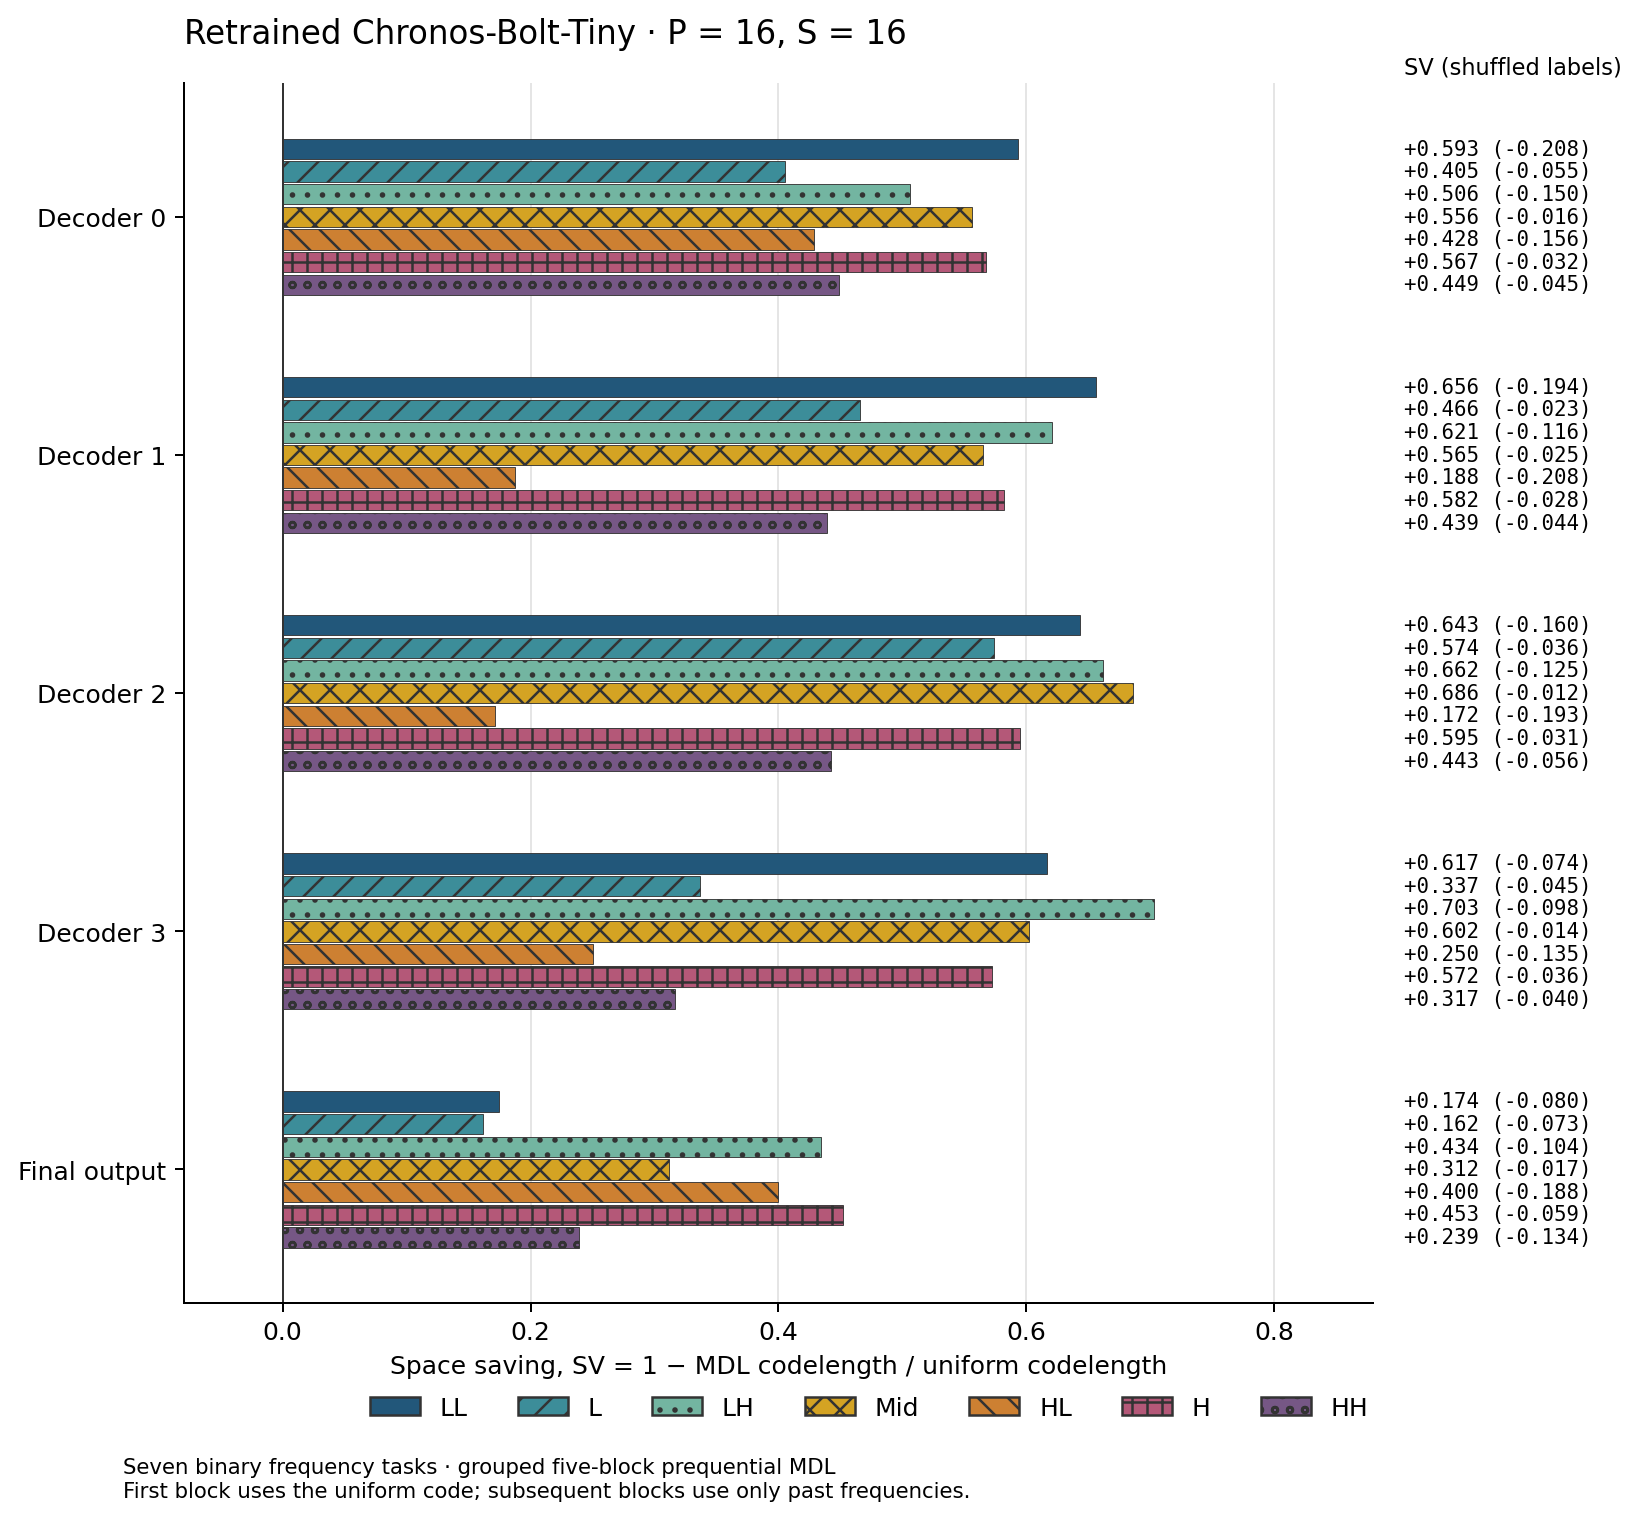

In [5]:
prefix = "smoke_" if MODE == "smoke" else ""
figure_paths = sorted(run_dir.rglob(f"{prefix}fig_probing_sv_p16_s16.png"))
if len(figure_paths) != 1:
    raise RuntimeError(f"Expected one reference figure, found {len(figure_paths)}.")
display(Image(filename=str(figure_paths[0]), width=1100))
print(figure_paths[0])

### Export inventory

In [6]:
exported = sorted(path for path in run_dir.rglob("*") if path.is_file() and path.suffix in {".png", ".pdf", ".tex", ".txt"})
print(f"{len(exported)} figure/caption export files; raw SV rows are also saved as CSV.")
display(pd.DataFrame({"export": [str(path.relative_to(run_dir)) for path in exported]}).head(18))

35 figure/caption export files; raw SV rows are also saved as CSV.


,export
0,fig_probing_sv_p16_s16.pdf
1,fig_probing_sv_p16_s16.png
2,fig_probing_sv_p16_s16_caption.txt
3,figures\sv_official-p16-s16.pdf
4,figures\sv_official-p16-s16.png
5,figures\sv_retrained-p16-s12.pdf
6,figures\sv_retrained-p16-s12.png
7,figures\sv_retrained-p16-s16.pdf
8,figures\sv_retrained-p16-s16.png
9,figures\sv_retrained-p16-s8.pdf


## Takeaways

The summary below is computed from the seven reference-checkpoint tasks.
Compare true-task and shuffled-control values before interpreting positive
SV as readable frequency structure. These are descriptive probes; they do
not decide the Bayesian hypotheses or establish causal relevance.

In [7]:
summary = reference.groupby("stage", sort=False).agg(
    tasks=("task", "size"),
    positive_sv_tasks=("SV", lambda values: int((values > 0).sum())),
    median_sv=("SV", "median"),
    median_shuffled_sv=("SV_shuffled", "median"),
).reindex(STAGE_ORDER)
display(summary.round(3))
if MODE == "smoke":
    display(Markdown("**Validation result only:** rerun in full mode before using the figure in the report."))
else:
    display(Markdown("The full-design exports are ready for the later Section 5.1 / Appendix F integration. The report source has not been changed."))

,tasks,positive_sv_tasks,median_sv,median_shuffled_sv
stage,,,,
dec_0,7,7,0.506,-0.055
dec_1,7,7,0.565,-0.044
dec_2,7,7,0.595,-0.056
dec_3,7,7,0.572,-0.045
output_head,7,7,0.312,-0.080


The full-design exports are ready for the later Section 5.1 / Appendix F integration. The report source has not been changed.